In [8]:
import numpy as np
import networkx as nx
import traci
import sumolib
import random

In [9]:

net = sumolib.net.readNet("data/tmp/tmp.net.xml")

Sumo_config = [
    'sumo',
    '-c', "data/tmp/tmp.sumocfg",
    '--step-length', '1',
    '--start'
]
traci.start(Sumo_config)
edges = net.getEdges()

 Retrying in 1 seconds


In [10]:
time_elapsed = 0
current_timestep = 0
travel_times = []
while time_elapsed < 15000:
    veh_id = f"ugv_{time_elapsed}"
    randomedge = random.choice(edges)._id
    traci.person.add(veh_id, randomedge, 0)
    traci.person.appendWalkingStage(veh_id, [randomedge], 
                                    arrivalPos=-1, speed=5.0)
    traci.simulationStep()
    time_elapsed = traci.simulation.getTime()
    start_time = time_elapsed
    while veh_id in traci.person.getIDList():
        traci.simulationStep()
        time_elapsed = traci.simulation.getTime()
    travel_times.append(time_elapsed - start_time)

In [11]:
traci.close()

Step #15004.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 7ms, vehicles TOT 0 ACT 0 BUF 0)       


In [12]:
travel_times = np.array(travel_times)
print(f"Average travel time: {np.mean(travel_times)} s")

Average travel time: 30.72093023255814 s


In [6]:
import pandas as pd

In [7]:
df = pd.read_csv("runs/dijkstra/simulation_results1.csv")
df

,start_idx,target_idx,warm_up_time,tour_start_time,total_time_taken,path_length
0,0,1,1000,1005,75,4
1,0,10,1000,1005,27,2
2,0,14,1000,1005,33,2
3,0,4,1000,1005,87,6
4,0,2,1000,1005,105,5
...,...,...,...,...,...,...
2315,79,30,1000,1005,18,3
2316,79,36,1000,1005,87,5
2317,79,44,1000,1005,213,11
2318,79,59,1000,1005,42,1


In [10]:
df[['total_time_taken', 'path_length']].describe()

,total_time_taken,path_length
count,2320.000000,2320.000000
mean,128.375431,6.129741
std,76.993467,3.342201
min,6.000000,1.000000
25%,66.000000,4.000000
50%,123.000000,6.000000
75%,183.000000,8.000000
max,372.000000,17.000000


In [1]:
import numpy as np
import time
import networkx as nx
import random
import pandas as pd
from tqdm import tqdm
from datetime import timedelta
from collections import defaultdict
import pickle
import yaml

import traci
import sumolib

In [2]:
Sumo_config = [
    'sumo',
    '-c', "data/tmp/tmp.sumocfg",
    '--step-length', '1',
    '--scale', '1',
    '--start'
]
traci.start(Sumo_config)

time_elapsed = 0
while time_elapsed < 15000:
    traci.simulationStep()
    time_elapsed = traci.simulation.getTime()

 Retrying in 1 seconds
Step #13400.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)      Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                       tep #4500.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)       tep #4500.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)       ep #9000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 0ms, vehicles TOT 0 ACT 0 BUF 0)        ep #9000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 0ms, vehicles TOT 0 ACT 0 BUF 0)        

In [3]:
def get_centroid(shape):
    """Calculates the center point of a shape (list of x,y tuples)."""
    if not shape:
        return 0, 0
    x_coords = [p[0] for p in shape]
    y_coords = [p[1] for p in shape]
    return np.mean(x_coords), np.mean(y_coords)

def build_graph(net_path,):
    net_path = net_path.replace('.sumocfg', '.net.xml')
    net = sumolib.net.readNet(net_path, withPedestrianConnections=True)
    junctions = net.getNodes()
    edge_eps = {}
    junc2nodes_map = defaultdict(list)
    
    for junction in junctions:
        connections = junction.getConnections()
        for connection in connections:
            # 1. Inspect the source of the connection
            ep = None
            edge = None
            dir = None
            if connection._from.getFunction() == 'walkingarea':
                ep = connection._from
                edge = connection._to
                dir = 0
            elif connection._to.getFunction() == 'walkingarea':
                ep = connection._to
                edge = connection._from
                dir = 1
            if ep and edge:
                edge_id = edge.getID()
                eps = [None, None]
                eps[dir] = ep
                if edge_id not in edge_eps:
                    edge_eps[edge_id] = {
                        "edge": edge,
                        "eps": eps
                    }
                else:
                    edge_eps[edge_id]["eps"][dir] = ep
                    if len([ep for ep in edge_eps[edge_id]["eps"] if ep is not None]) > 2:
                        print("More than 2 entry points for edge ", edge_id)
                        raise ValueError("More than 2 entry points for edge ", edge_id)

    G = nx.DiGraph()
    for edge_id, edge_data in edge_eps.items():
        entry_points = edge_data["eps"]
        for ep in entry_points:
            shape = ep.getShape()
            cx, cy = get_centroid(shape)
            G.add_node(ep._id, junc_id=ep._from._id,junc_coord=ep._from._coord, x=cx, y=cy)
            junc2nodes_map[ep._from._id].append(ep._id)
        edge_obj = edge_data["edge"]
        edge_length = None
        edge_type = edge_obj.getFunction()
        edge_est_tt = None
        edge_mean_speed = None
        for lane_obj in edge_obj.getLanes():
            if "pedestrian" in lane_obj._allowed:
                edge_est_tt = traci.lane.getTraveltime(lane_obj.getID())
                edge_mean_speed = traci.lane.getLastStepMeanSpeed(lane_obj.getID())
        if edge_type == 'crossing':
            edge_length = 5.0
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type,
                        est_tt=edge_est_tt, mean_speed = edge_mean_speed)
            # G.add_edge(entry_points[1]._id, entry_points[0]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
        else:
            edge_length = edge_obj.getLength()
            edge_type = 'sidewalk'
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type, 
                       est_tt=edge_est_tt, mean_speed=edge_mean_speed)
    
    G_und = G.to_undirected()



    all_shortest_path_lengths = dict(nx.all_pairs_dijkstra_path_length(G_und, weight='length'))
    return G_und, G, all_shortest_path_lengths, junc2nodes_map

net_path = "data/tmp/tmp.net.xml"
G, G_dir, all_shortest_path_lengths, junc2nodes_map = build_graph(net_path,)
junction_list = list(junc2nodes_map.keys())
node2idx = {node: idx for idx, node in enumerate(sorted(G.nodes))}
idx2node = {idx: node for node, idx in node2idx.items()}
traci.close()

Step #15000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 85ms, vehicles TOT 0 ACT 0 BUF 0)      


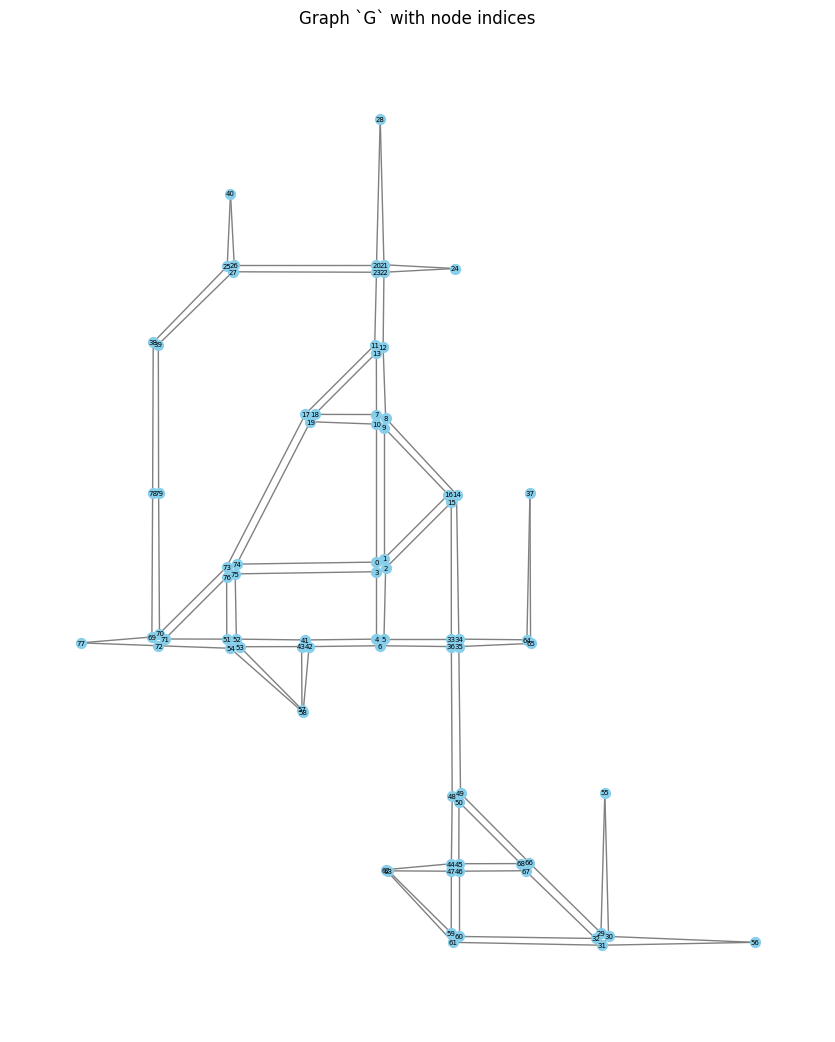

In [4]:
# Plot Graph G and label nodes with their indices
import matplotlib.pyplot as plt

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Labels: map node -> index from node2idx
labels = {n: node2idx[n] for n in G.nodes()}

plt.figure(figsize=(10, 10))
# Draw nodes and edges
nx.draw(G, pos=pos, with_labels=False, node_size=50, node_color='skyblue', edge_color='gray')
# Draw labels (node indices)
nx.draw_networkx_labels(G, pos, labels=labels, font_size=5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Graph `G` with node indices')
plt.axis('off')
plt.show()


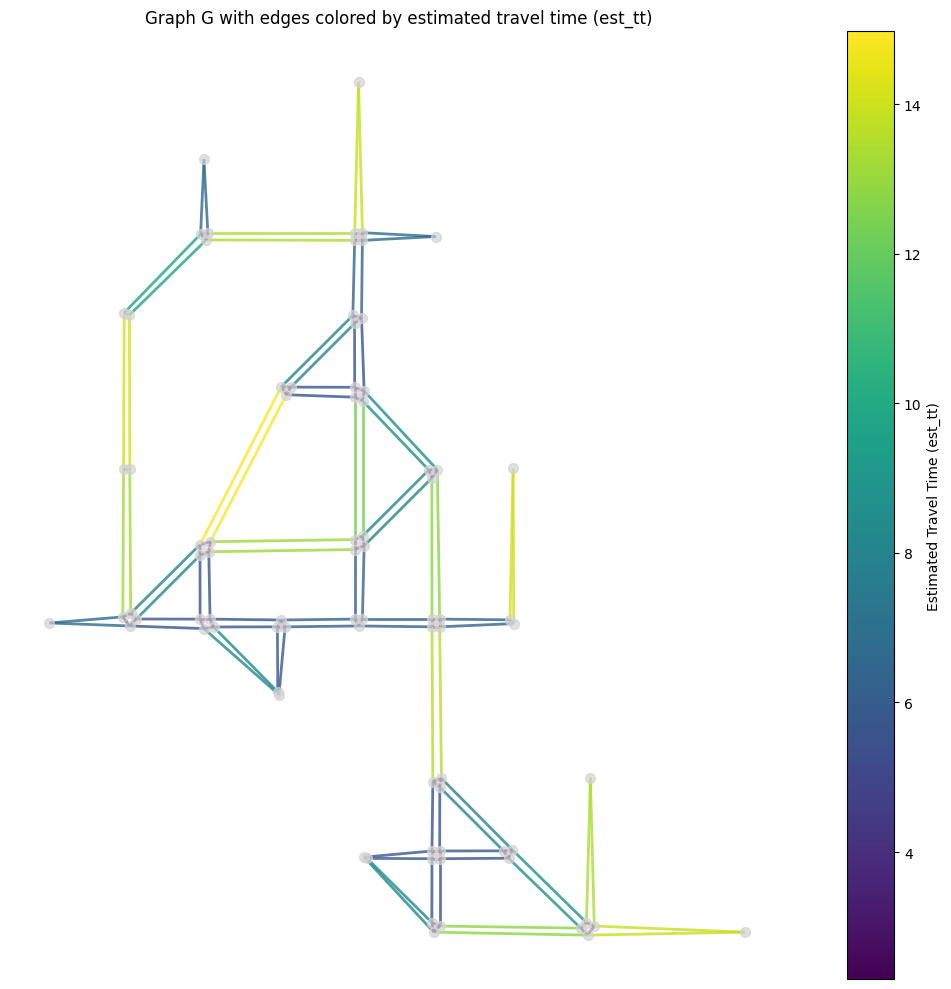

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Extract est_tt values for edges
edge_est_tt = []
edges_with_tt = []
for u, v, data in G.edges(data=True):
    if 'est_tt' in data and data['est_tt'] is not None:
        edge_est_tt.append(data['est_tt'])
        edges_with_tt.append((u, v))

# Create colormap
if edge_est_tt:
    vmin = min(edge_est_tt)
    vmax = max(edge_est_tt)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.cm.viridis
    
    plt.figure(figsize=(12, 10))
    
    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color='lightgray', alpha=0.7)
    
    # Draw edges with color based on est_tt
    for (u, v), tt in zip(edges_with_tt, edge_est_tt):
        nx.draw_networkx_edges(G, pos, [(u, v)], 
                              edge_color=[cmap(norm(tt))], 
                              width=2, alpha=0.8)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca(), label='Estimated Travel Time (est_tt)')
    
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title('Graph G with edges colored by estimated travel time (est_tt)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No edges with est_tt values found.")

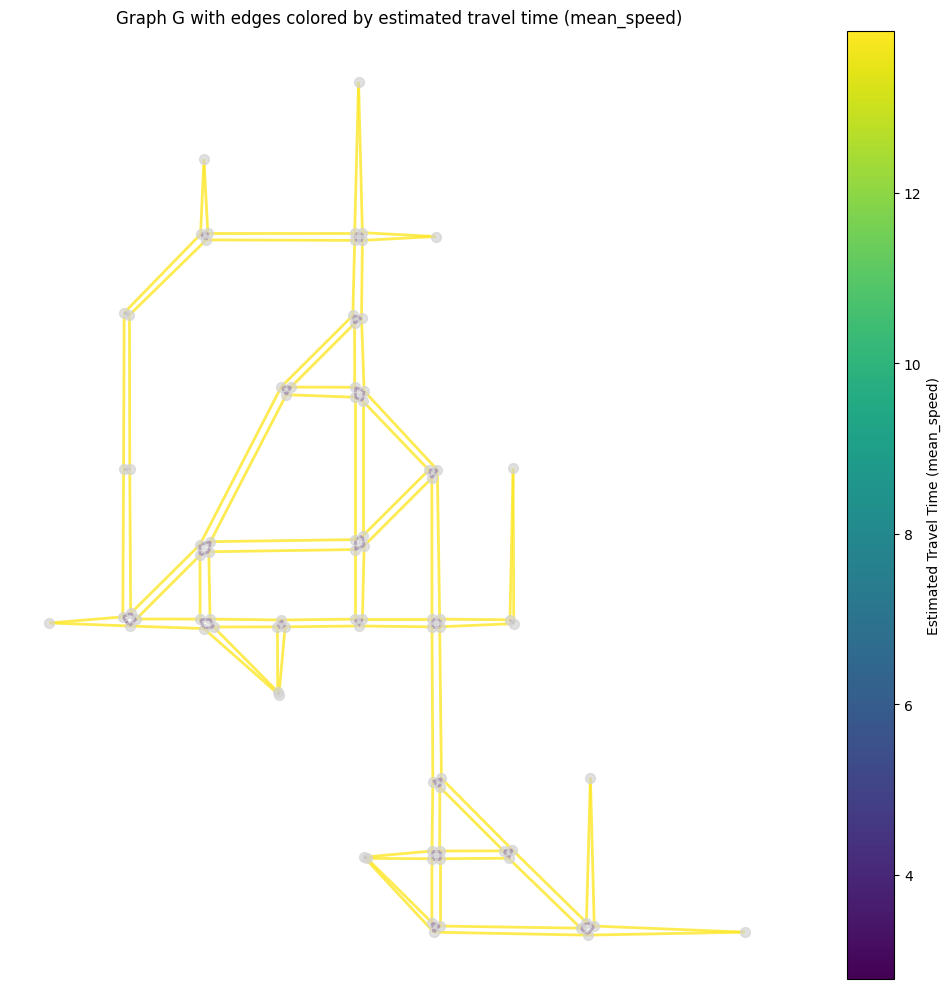

In [6]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Extract mean_speed values for edges
edge_mean_speed = []
edges_with_tt = []
for u, v, data in G.edges(data=True):
    if 'mean_speed' in data and data['mean_speed'] is not None:
        edge_mean_speed.append(data['mean_speed'])
        edges_with_tt.append((u, v))

# Create colormap
if edge_mean_speed:
    vmin = min(edge_mean_speed)
    vmax = max(edge_mean_speed)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.cm.viridis
    
    plt.figure(figsize=(12, 10))
    
    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color='lightgray', alpha=0.7)
    
    # Draw edges with color based on mean_speed
    for (u, v), tt in zip(edges_with_tt, edge_mean_speed):
        nx.draw_networkx_edges(G, pos, [(u, v)], 
                              edge_color=[cmap(norm(tt))], 
                              width=2, alpha=0.8)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca(), label='Estimated Travel Time (mean_speed)')
    
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title('Graph G with edges colored by estimated travel time (mean_speed)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No edges with mean_speed values found.")